# Hotel Booking Demand

In [ ]:
## Business Background

Imagine you have been hired as a Data Analyst for a hotel chain.

The hotel has two types of properties:

Resort Hotel
City Hotel

Recently, management noticed several problems:

Many customers book rooms but cancel before arrival.
Some months have low occupancy, causing revenue loss.
Management doesn't know which customers are most likely to cancel.
Room pricing may not be optimized.
Marketing campaigns are not targeting the right customer segments.

In [ ]:
# Problem Statement

## Business Objective:

Analyze hotel booking data to identify the causes of booking cancellations, understand customer booking behavior, improve room occupancy, and provide data-driven recommendations that increase revenue and reduce losses.

This is the central business problem your project will solve.

Examples include:

- Why are bookings being canceled?
- Which customers cancel the most?
- Which months have the lowest occupancy?
- Which hotel performs better?
- Which market segment generates the highest revenue

##**Underastanding The Data**

| Column                             | Meaning                                                     | Business Importance                                      |
| ---------------------------------- | ----------------------------------------------------------- | -------------------------------------------------------- |
| **hotel**                          | Type of hotel (`Resort Hotel` or `City Hotel`)              | Compare performance between hotel types.                 |
| **is_canceled**                    | Whether the booking was canceled (1 = Yes, 0 = No)          | Main metric for analyzing cancellation rates.            |
| **lead_time**                      | Number of days between booking and arrival                  | Helps understand booking behavior and cancellation risk. |
| **arrival_date_year**              | Year of arrival                                             | Analyze yearly trends.                                   |
| **arrival_date_month**             | Month of arrival                                            | Identify seasonal demand.                                |
| **arrival_date_week_number**       | Week of the year                                            | Analyze weekly booking patterns.                         |
| **arrival_date_day_of_month**      | Day of arrival                                              | Study daily booking distribution.                        |
| **stays_in_weekend_nights**        | Number of weekend nights booked                             | Understand weekend travel behavior.                      |
| **stays_in_week_nights**           | Number of weekday nights booked                             | Measure weekday occupancy.                               |
| **adults**                         | Number of adults                                            | Analyze customer group sizes.                            |
| **children**                       | Number of children                                          | Identify family bookings.                                |
| **babies**                         | Number of babies                                            | Understand customer demographics.                        |
| **meal**                           | Meal plan selected (BB, HB, FB, etc.)                       | Evaluate meal package popularity.                        |
| **country**                        | Customer's country                                          | Identify top customer markets.                           |
| **market_segment**                 | How the booking was made (Online, Corporate, Offline, etc.) | Determine which channels generate the most bookings.     |
| **distribution_channel**           | Booking distribution channel                                | Analyze booking sources.                                 |
| **is_repeated_guest**              | Whether the guest has stayed before                         | Measure customer loyalty.                                |
| **previous_cancellations**         | Number of previous cancellations by the guest               | Identify high-risk customers.                            |
| **previous_bookings_not_canceled** | Previous successful bookings                                | Analyze loyal customers.                                 |
| **reserved_room_type**             | Room type originally booked                                 | Understand booking preferences.                          |
| **assigned_room_type**             | Room actually assigned                                      | Detect room upgrades or changes.                         |
| **booking_changes**                | Number of modifications before arrival                      | Analyze booking flexibility.                             |
| **deposit_type**                   | Deposit policy (`No Deposit`, `Refundable`, `Non Refund`)   | Study its effect on cancellations.                       |
| **agent**                          | Travel agent ID                                             | Compare booking performance by agents.                   |
| **company**                        | Company ID (for corporate bookings)                         | Analyze business customers.                              |
| **days_in_waiting_list**           | Days the booking stayed on the waiting list                 | Measure booking delays.                                  |
| **customer_type**                  | Type of customer (`Transient`, `Group`, `Contract`, etc.)   | Segment customers.                                       |
| **adr**                            | Average Daily Rate (price per room per night)               | Key revenue metric.                                      |
| **required_car_parking_spaces**    | Parking spaces requested                                    | Plan parking resources.                                  |
| **total_of_special_requests**      | Number of special requests                                  | Measure guest preferences and service quality.           |
| **reservation_status**             | Final booking status (`Check-Out`, `Canceled`, `No-Show`)   | Understand booking outcomes.                             |
| **reservation_status_date**        | Date of final reservation status                            | Analyze cancellation and check-out trends over time.     |


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import os

folder =  r"C:\Users\hp\Downloads\archive (35)"
print(os.listdir(folder))

['hotel_bookings.csv']


In [5]:

df = pd.read_csv(r"C:\Users\hp\Downloads\archive (35)\hotel_bookings.csv")

In [6]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [8]:
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

In [17]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [20]:
df.duplicated().sum()

31994

In [21]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


## Exploratory Data Analysis (EDA)

In [ ]:
How many total bookings are there?
How many bookings were canceled?
Which hotel has more bookings?
Which months have the highest bookings?
Which countries bring the most customers?
Which room type is booked most often?
How far in advance do customers book?

In [24]:
df.shape[0]

119390

In [27]:
total_bookings = len(df)
total_bookings

119390

## Which hotel has more bookings?

In [31]:
hotel_count = df["hotel"].value_counts()
hotel_count

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

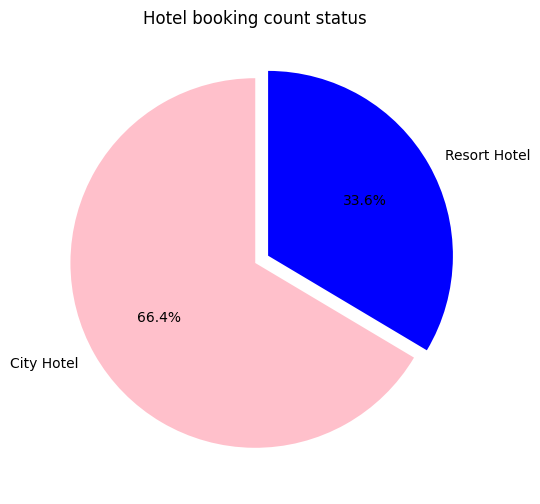

In [35]:
import matplotlib.pyplot as plt

canceled_booking = df["hotel"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(canceled_booking,
        labels=['City Hotel', 'Resort Hotel'],
        autopct='%1.1f%%',
        startangle=90,
        colors=['pink','blue'],
        explode=(0,0.08))

plt.title("Hotel booking count status")
plt.show()

## How many bookings were canceled?

In [32]:
canceled_booking= df["is_canceled"].value_counts()
canceled_booking

is_canceled
0    75166
1    44224
Name: count, dtype: int64

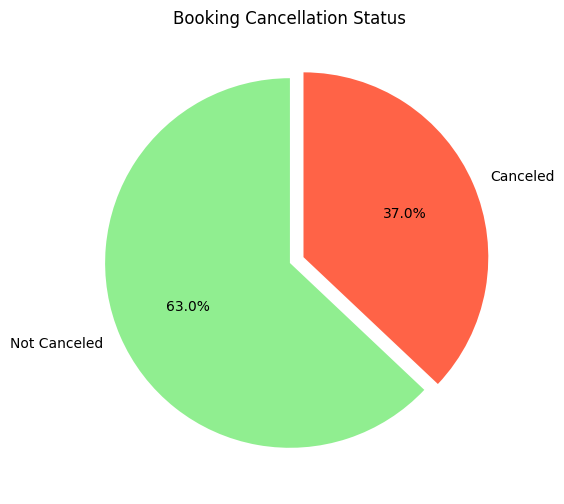

In [33]:
import matplotlib.pyplot as plt

canceled_booking = df["is_canceled"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(canceled_booking,
        labels=['Not Canceled', 'Canceled'],
        autopct='%1.1f%%',
        startangle=90,
        colors=['lightgreen','tomato'],
        explode=(0,0.08))

plt.title("Booking Cancellation Status")
plt.show()

## Which Hotel has highest cancellation rate?

In [36]:
cancellation_rate = (
    df.groupby("hotel")["is_canceled"]
      .mean() * 100
)

print(cancellation_rate)

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64


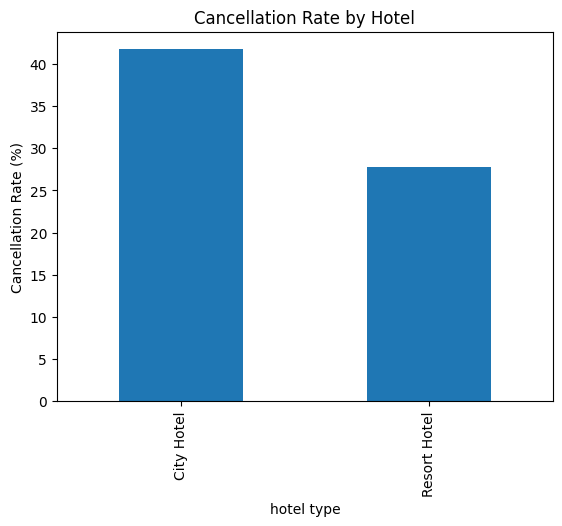

In [40]:
cancellation_rate.plot(kind="bar")

plt.title("Cancellation Rate by Hotel")
plt.xlabel("hotel type")
plt.ylabel("Cancellation Rate (%)")
plt.show()

## Business Insight

**City Hotel** has both the highest number of cancellations and a higher cancellation rate than **Resort Hotel.** This may indicate issues such as more flexible cancellation policies, different customer behavior, or booking channel differences. Management should investigate these factors to reduce revenue loss and improve occupancy.

**Insight:** The City Hotel has a higher cancellation rate than the Resort Hotel.

**Business Impact:** This results in empty rooms and lost revenue.

**Recommendation:** Introduce flexible rebooking options or require a partial advance payment during high-demand periods.

## Which months have the highest bookings?

In [42]:
monthly_bookings = df.groupby("arrival_date_month").size()

print(monthly_bookings)

arrival_date_month
April        11089
August       13877
December      6780
February      8068
January       5929
July         12661
June         10939
March         9794
May          11791
November      6794
October      11160
September    10508
dtype: int64


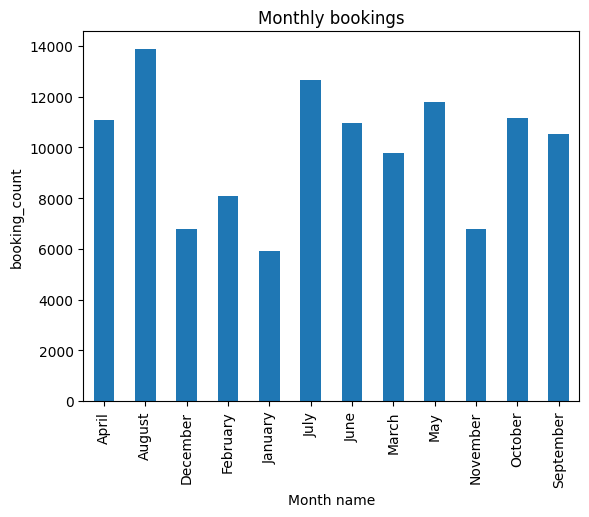

In [44]:
monthly_bookings.plot(kind="bar")


plt.title("Monthly bookings")
plt.xlabel("Month name")
plt.ylabel("booking_count")
plt.show()

## Business Insight

August recorded the highest number of hotel bookings, indicating peak travel demand during this month. The hotel should ensure sufficient staff, room availability, and inventory during August. Conversely, months with fewer bookings may benefit from promotional offers or discounts to improve occupancy.

## Mapping the Country Names with Country Codes

In [30]:
country_mapping = {
    'PRT': 'Portugal',
    'GBR': 'United Kingdom',
    'USA': 'United States',
    'ESP': 'Spain',
    'IRL': 'Ireland',
    'FRA': 'France',
    'NULL': None,
    'ROU': 'Romania',
    'NOR': 'Norway',
    'OMN': 'Oman',
    'ARG': 'Argentina',
    'POL': 'Poland',
    'DEU': 'Germany',
    'BEL': 'Belgium',
    'CHE': 'Switzerland',
    'CN': 'China',
    'GRC': 'Greece',
    'ITA': 'Italy',
    'NLD': 'Netherlands',
    'DNK': 'Denmark',
    'RUS': 'Russia',
    'SWE': 'Sweden',
    'AUS': 'Australia',
    'EST': 'Estonia',
    'CZE': 'Czechia',
    'BRA': 'Brazil',
    'FIN': 'Finland',
    'MOZ': 'Mozambique',
    'BWA': 'Botswana',
    'LUX': 'Luxembourg',
    'SVN': 'Slovenia',
    'ALB': 'Albania',
    'IND': 'India',
    'CHN': 'China',
    'MEX': 'Mexico',
    'MAR': 'Morocco',
    'UKR': 'Ukraine',
    'SMR': 'San Marino',
    'LVA': 'Latvia',
    'PRI': 'Puerto Rico',
    'SRB': 'Serbia',
    'CHL': 'Chile',
    'AUT': 'Austria',
    'BLR': 'Belarus',
    'LTU': 'Lithuania',
    'TUR': 'Turkey',
    'ZAF': 'South Africa',
    'AGO': 'Angola',
    'ISR': 'Israel',
    'CYM': 'Cayman Islands',
    'ZMB': 'Zambia',
    'CPV': 'Cape Verde',
    'ZWE': 'Zimbabwe',
    'DZA': 'Algeria',
    'KOR': 'South Korea',
    'CRI': 'Costa Rica',
    'HUN': 'Hungary',
    'ARE': 'United Arab Emirates',
    'TUN': 'Tunisia',
    'JAM': 'Jamaica',
    'HRV': 'Croatia',
    'HKG': 'Hong Kong',
    'IRN': 'Iran',
    'GEO': 'Georgia',
    'AND': 'Andorra',
    'GIB': 'Gibraltar',
    'URY': 'Uruguay',
    'JEY': 'Jersey',
    'CAF': 'Central African Republic',
    'CYP': 'Cyprus',
    'COL': 'Colombia',
    'GGY': 'Guernsey',
    'KWT': 'Kuwait',
    'NGA': 'Nigeria',
    'MDV': 'Maldives',
    'VEN': 'Venezuela',
    'SVK': 'Slovakia',
    'FJI': 'Fiji',
    'KAZ': 'Kazakhstan',
    'PAK': 'Pakistan',
    'IDN': 'Indonesia',
    'LBN': 'Lebanon',
    'PHL': 'Philippines',
    'SEN': 'Senegal',
    'SYC': 'Seychelles',
    'AZE': 'Azerbaijan',
    'BHR': 'Bahrain',
    'NZL': 'New Zealand',
    'THA': 'Thailand',
    'DOM': 'Dominican Republic',
    'MKD': 'North Macedonia',
    'MYS': 'Malaysia',
    'ARM': 'Armenia',
    'JPN': 'Japan',
    'LKA': 'Sri Lanka',
    'CUB': 'Cuba',
    'CMR': 'Cameroon',
    'BIH': 'Bosnia and Herzegovina',
    'MUS': 'Mauritius',
    'COM': 'Comoros',
    'SUR': 'Suriname',
    'UGA': 'Uganda',
    'BGR': 'Bulgaria',
    'CIV': "Côte d'Ivoire",
    'JOR': 'Jordan',
    'SYR': 'Syria',
    'SGP': 'Singapore',
    'BDI': 'Burundi',
    'SAU': 'Saudi Arabia',
    'VNM': 'Vietnam',
    'PLW': 'Palau',
    'QAT': 'Qatar',
    'EGY': 'Egypt',
    'PER': 'Peru',
    'MLT': 'Malta',
    'MWI': 'Malawi',
    'ECU': 'Ecuador',
    'MDG': 'Madagascar',
    'ISL': 'Iceland',
    'UZB': 'Uzbekistan',
    'NPL': 'Nepal',
    'BHS': 'Bahamas',
    'MAC': 'Macau',
    'TGO': 'Togo',
    'TWN': 'Taiwan',
    'DJI': 'Djibouti',
    'STP': 'São Tomé and Príncipe',
    'KNA': 'Saint Kitts and Nevis',
    'ETH': 'Ethiopia',
    'IRQ': 'Iraq',
    'HND': 'Honduras',
    'RWA': 'Rwanda',
    'KHM': 'Cambodia',
    'MCO': 'Monaco',
    'BGD': 'Bangladesh',
    'IMN': 'Isle of Man',
    'TJK': 'Tajikistan',
    'NIC': 'Nicaragua',
    'BEN': 'Benin',
    'VGB': 'British Virgin Islands',
    'TZA': 'Tanzania',
    'GAB': 'Gabon',
    'GHA': 'Ghana',
    'TMP': 'East Timor',
    'GLP': 'Guadeloupe',
    'KEN': 'Kenya',
    'LIE': 'Liechtenstein',
    'GNB': 'Guinea-Bissau',
    'MNE': 'Montenegro',
    'UMI': 'United States Minor Outlying Islands',
    'MYT': 'Mayotte',
    'FRO': 'Faroe Islands',
    'MMR': 'Myanmar',
    'PAN': 'Panama',
    'BFA': 'Burkina Faso',
    'LBY': 'Libya',
    'MLI': 'Mali',
    'NAM': 'Namibia',
    'BOL': 'Bolivia',
    'PRY': 'Paraguay',
    'BRB': 'Barbados',
    'ABW': 'Aruba',
    'AIA': 'Anguilla',
    'SLV': 'El Salvador',
    'DMA': 'Dominica',
    'PYF': 'French Polynesia',
    'GUY': 'Guyana',
    'LCA': 'Saint Lucia',
    'ATA': 'Antarctica',
    'GTM': 'Guatemala',
    'ASM': 'American Samoa',
    'MRT': 'Mauritania',
    'NCL': 'New Caledonia',
    'KIR': 'Kiribati',
    'SDN': 'Sudan',
    'ATF': 'French Southern Territories',
    'SLE': 'Sierra Leone',
    'LAO': 'Laos',
}

In [31]:
df['country'] = df['country'].replace(country_mapping)

## Which countries bring the most customers?

| Code | Country        |
| ---- | -------------- |
| PRT  | Portugal       |
| GBR  | United Kingdom |
| ESP  | Spain          |
| FRA  | France         |
| DEU  | Germany        |
| ITA  | Italy          |
| USA  | United States  |
| BRA  | Brazil         |
| BEL  | Belgium        |
| NLD  | Netherlands    |
| IRL  | Ireland        |
| CHE  | Switzerland    |
| AUT  | Austria        |
| CHN  | China          |
| JPN  | Japan          |
| IND  | India          |
| RUS  | Russia         |
| CAN  | Canada         |
| MEX  | Mexico         |
| AUS  | Australia      |
| POL  | Poland         |
| SWE  | Sweden         |
| NOR  | Norway         |
| DNK  | Denmark        |
| FIN  | Finland        |


In [18]:
country_wise_booking= df["country"].value_counts()
print(country_wise_booking.head(1))

country
Portugal    48590
Name: count, dtype: int64


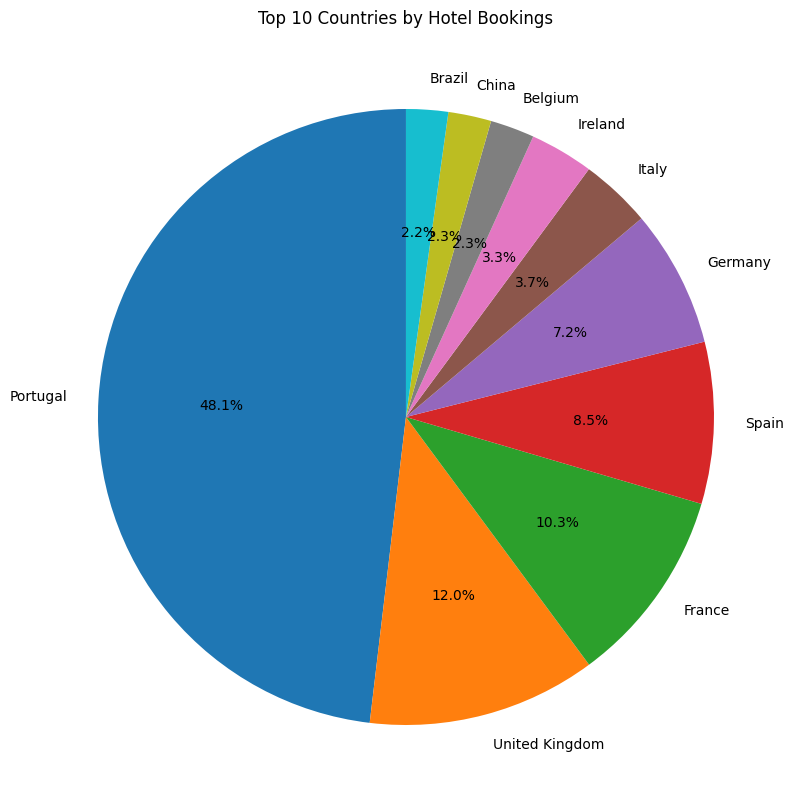

In [19]:
import matplotlib.pyplot as plt

country_wise_booking = df['country'].value_counts()

plt.figure(figsize=(10, 10))

country_wise_booking.head(10).plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Top 10 Countries by Hotel Bookings')
plt.ylabel('')
plt.show()

- Portugal (PRT) has the highest number of hotel bookings (`48,590 bookings`). `This indicates that the hotel chain's largest customer base comes from Portugal, so management should focus marketing campaigns and customer retention strategies on this market while exploring opportunities to increase bookings from other countries`.

## Which countries have the highest cancellation rates?

In [20]:
cancellation_rate = (
    df.groupby('country')['is_canceled']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(cancellation_rate.head(10))

country
Isle of Man                             100.0
United States Minor Outlying Islands    100.0
Fiji                                    100.0
Guadeloupe                              100.0
Mayotte                                 100.0
Guernsey                                100.0
Nicaragua                               100.0
Honduras                                100.0
Cambodia                                100.0
British Virgin Islands                  100.0
Name: is_canceled, dtype: float64


In [21]:
country_data = df.groupby('country').agg(
    total_bookings=('is_canceled', 'count'),
    cancelled_bookings=('is_canceled', 'sum')
)

country_data['cancellation_rate'] = (
    country_data['cancelled_bookings']
    / country_data['total_bookings'] * 100
)

result = country_data[
    country_data['total_bookings'] >= 100
].sort_values('cancellation_rate', ascending=False)

print(result.head(10))

             total_bookings  cancelled_bookings  cancellation_rate
country                                                           
Portugal              48590               27519          56.635110
Angola                  362                 205          56.629834
Morocco                 259                 109          42.084942
South Korea             133                  55          41.353383
Turkey                  248                 102          41.129032
Luxembourg              287                 109          37.979094
Russia                  632                 239          37.816456
Brazil                 2224                 830          37.320144
Italy                  3766                1333          35.395645
Hungary                 230                  77          33.478261


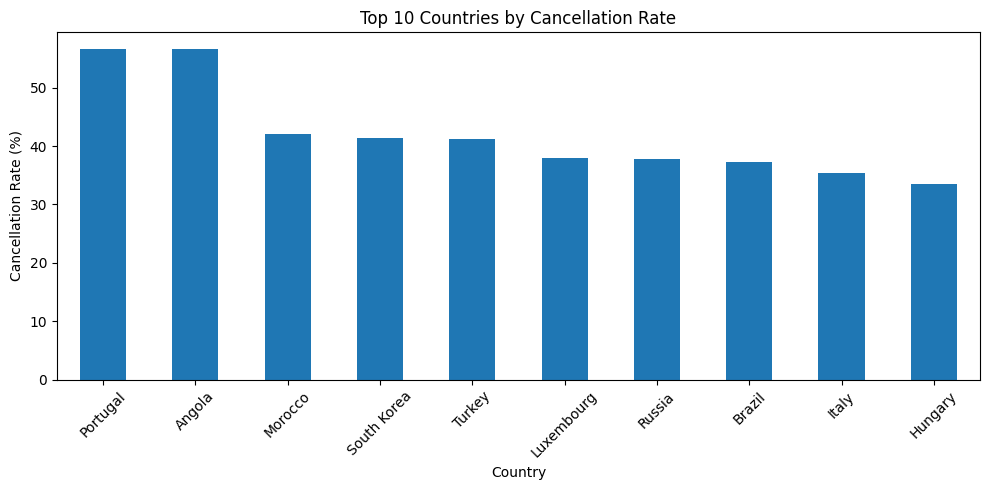

In [27]:
import matplotlib.pyplot as plt

# Select the top 10 countries
top_10 = result.head(10)

# Create a bar chart
top_10['cancellation_rate'].plot(
    kind='bar',
    figsize=(10, 5),
    title='Top 10 Countries by Cancellation Rate'
)


plt.xlabel('Country')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

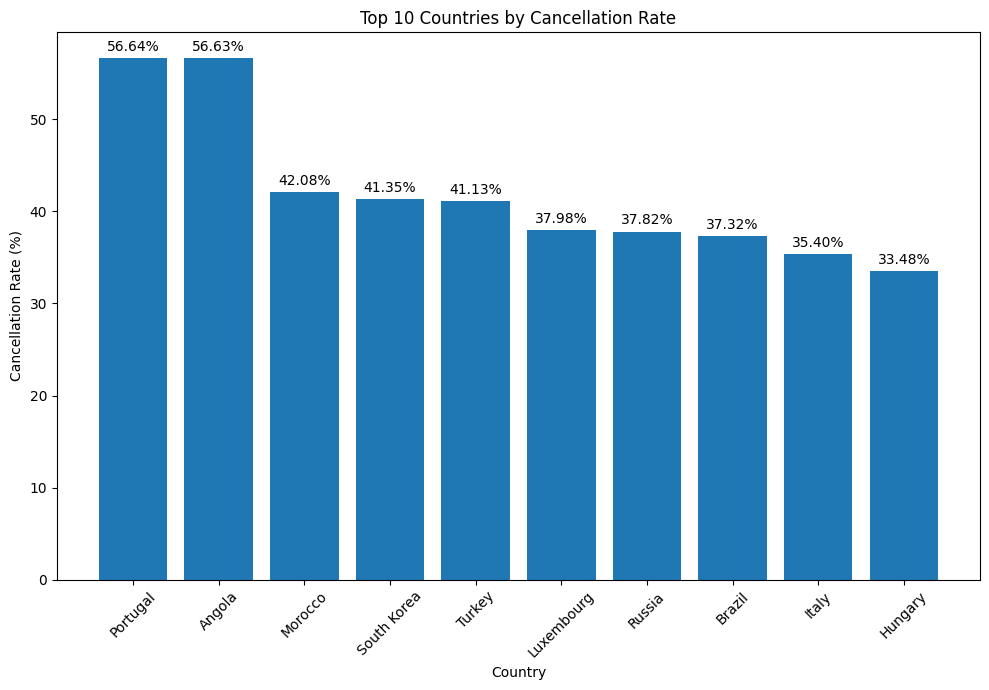

In [29]:
import matplotlib.pyplot as plt

top_10 = result.head(10)

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.bar(
    top_10.index,
    top_10['cancellation_rate']
)

# Add data labels
ax.bar_label(bars, fmt='%.2f%%', padding=3)

ax.set_title('Top 10 Countries by Cancellation Rate')
ax.set_xlabel('Country')
ax.set_ylabel('Cancellation Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The country-wise analysis shows that Portugal has the highest cancellation rate among the top 10 countries analyzed, at 56.64%, with 27,519 cancelled bookings. Angola follows closely at 56.63%, but with a much smaller booking volume. These findings suggest that the business should investigate the factors driving cancellations, prioritizing countries with both high cancellation rates and high cancellation volumes to identify opportunities to reduce lost bookings.

In [12]:
result_df = pd.DataFrame(result)
result_df.head

,total_bookings,cancelled_bookings,cancellation_rate
country,,,
PRT,48590,27519,56.635110
AGO,362,205,56.629834
CHN,999,462,46.246246
MAR,259,109,42.084942
KOR,133,55,41.353383


## Cancellation Analaysis

## 1. Overall cancellation rate

In [35]:
total_bookings = len(df)
cancelled = df['is_canceled'].sum()

cancellation_rate = cancelled /total_bookings *100

print("Total bookings :",total_bookings)
print("cancellation bookings:", cancelled)
print("Cancellation rate:", round(cancellation_rate,2), "%")

Total bookings : 119390
cancellation bookings: 44224
Cancellation rate: 37.04 %


## 2. Analyze cancellations by hotel type

In [36]:
hotel_cancel = df.groupby('hotel')['is_canceled'].mean() * 100

print(hotel_cancel.sort_values(ascending=False))

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64


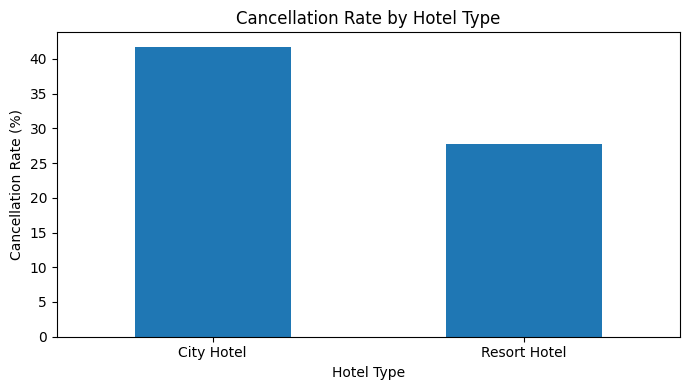

In [37]:
hotel_cancel.plot(kind='bar', figsize=(7, 4))

plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Insight:
- City Hotels have a substantially higher cancellation rate than Resort Hotels.
- The difference is approximately 14 percentage points.
- The business should investigate whether booking flexibility, customer mix, deposit policies, or booking lead times help explain this difference.
Recommendation: Review cancellation patterns for City Hotels and compare them with Resort Hotels to identify opportunities to reduce cancellations.

**Insight to look for**: Compare City Hotel and Resort Hotel cancellation rates. The hotel with the higher rate may need closer investigation.

## 4. Analyze monthly cancellations

In [38]:
monthly_cancel = df.groupby('arrival_date_month')['is_canceled'].mean() * 100

print(monthly_cancel.sort_values(ascending=False))

arrival_date_month
June         41.457172
April        40.797186
May          39.665847
September    39.170156
October      38.046595
August       37.753117
July         37.453598
December     34.970501
February     33.415964
March        32.152338
November     31.233441
January      30.477315
Name: is_canceled, dtype: float64


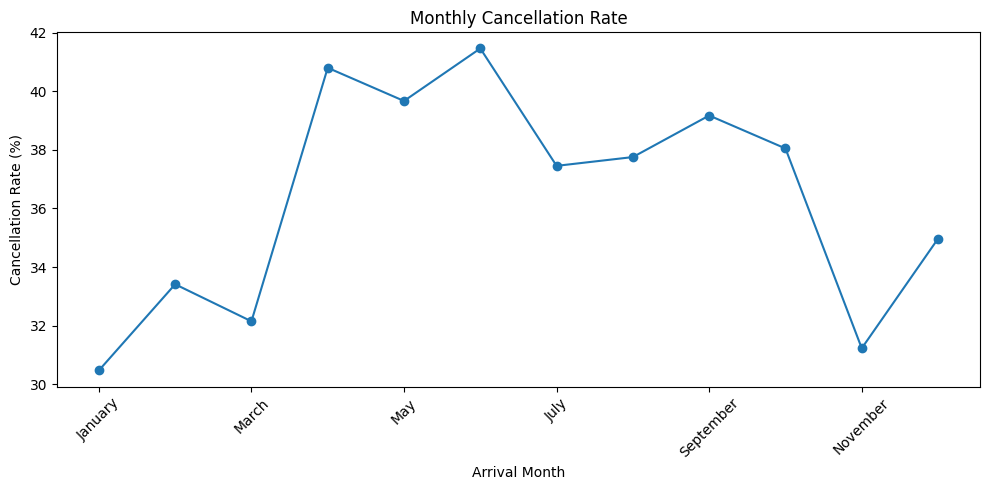

In [39]:
months = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_cancel = monthly_cancel.reindex(months)

monthly_cancel.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Monthly Cancellation Rate')
plt.xlabel('Arrival Month')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Insight:
- June has the highest cancellation rate in your chart, at approximately 41.5%.
- January has the lowest rate, at approximately 30.5%.
- Cancellation rates vary considerably by arrival month.
Recommendation: Investigate why cancellation rates rise during certain months. Compare monthly booking volumes and seasonal demand before deciding whether these changes represent a business problem.
Note: The chart labels are partially cut off in the screenshot, so the values above are approximate readings. February and December should also be checked in your underlying data

**Insight to look for**: Identify months with unusually high cancellation rates. This can help the business investigate seasonal patterns.

## 5. Analyze cancellation by deposit type

In [40]:
deposit_cancel = df.groupby('deposit_type').agg(
    total_bookings=('is_canceled', 'count'),
    cancelled_bookings=('is_canceled', 'sum'),
    cancellation_rate=('is_canceled', 'mean')
)

deposit_cancel['cancellation_rate'] *= 100

print(deposit_cancel.sort_values(
    'cancellation_rate', ascending=False
))

              total_bookings  cancelled_bookings  cancellation_rate
deposit_type                                                       
Non Refund             14587               14494          99.362446
No Deposit            104641               29694          28.377022
Refundable               162                  36          22.222222


Insight:
- Non Refund bookings have an extremely high cancellation rate of 99.36%.
- No Deposit bookings have a cancellation rate of 28.38%.
- Refundable bookings have the lowest rate, at 22.22%, but there are only 162 bookings in this category.
Important business finding: The 99.36% cancellation rate for Non Refund bookings is unusual. Before making a recommendation, verify the dataset's deposit definitions, booking status, and coding. The result may be correct, but it deserves investigation.
Recommendation: Investigate the Non Refund category first and check whether the cancellation figures are consistent with the business rules. Do not assume the deposit policy caused the cancellations just from this analysis.

## 6. Analyze lead time
`Lead time means the number of days between booking and the scheduled arrival date.`

In [41]:
bins = [-1, 7, 30, 90, 180, float('inf')]
labels = ['0-7 days', '8-30 days', '31-90 days',
          '91-180 days', '180+ days']

df['lead_time_group'] = pd.cut(
    df['lead_time'],
    bins=bins,
    labels=labels
)

lead_cancel = df.groupby(
    'lead_time_group', observed=False
)['is_canceled'].mean() * 100

print(lead_cancel)

lead_time_group
0-7 days        9.632331
8-30 days      27.863924
31-90 days     37.698372
91-180 days    44.710466
180+ days      57.010368
Name: is_canceled, dtype: float64


Insight:
- Bookings made more than 180 days in advance have the highest cancellation rate at 57.01%.
- Bookings made within seven days of arrival have the lowest rate at 9.63%.
- The cancellation rate increases consistently across the five lead-time groups.
Business interpretation: Customers who book far in advance may have more time for their plans to change, which could contribute to cancellations. This is a possible explanation, not a proven cause.
Recommendation: Consider targeted confirmation messages, reminders, or appropriate booking policies for reservations made far in advance.

## Overall business conclusions

Long lead times are associated with higher cancellations.
The rate rises from 9.63% for bookings made 0–7 days ahead to 57.01% for bookings made more than 180 days ahead.




City Hotels have a higher cancellation rate.
The chart shows approximately 41.7% for City Hotels versus 27.8% for Resort Hotels.




Deposit type deserves further investigation.
The Non Refund category has a 99.36% cancellation rate, which should be validated before drawing conclusions.




Cancellation patterns differ across countries.
Portugal is a priority for investigation because of its high cancellation rate and high booking volume.




Monthly patterns may help with planning.
June has the highest rate in the displayed chart. Further analysis can help determine whether seasonality or customer mix is associated with the change.

In [28]:
df['country'] = df['country'].replace(country_mapping)

In [31]:
df['country']

0               Portugal
1               Portugal
2         United Kingdom
3         United Kingdom
4         United Kingdom
               ...      
119385           Belgium
119386            France
119387           Germany
119388    United Kingdom
119389           Germany
Name: country, Length: 119390, dtype: object